## State

In [ ]:
from __future__ import annotations

from typing import Literal, TypedDict

PropertyType = Literal["apartment", "house", "workspace"]

class Listing(TypedDict):
    id: str
    property_type: PropertyType
    city: str
    neighborhood: str
    title: str
    price_per_month: int
    bedrooms: int

class RealEstateState(TypedDict):
    phase: str
    user_message: str
    assistant_message: str
    property_type: PropertyType | None
    city: str | None
    neighbourhood: str | None
    listings: list[Listing]

In [3]:
def initial_state() -> RealEstateState:
    return {
        "phase": "new",
        "property_type": None,
        "city": None,
        "neighborhood": None,
        "listings": [],
    }

initial_state()

{'phase': 'new',
 'property_type': None,
 'city': None,
 'neighborhood': None,
 'listings': []}

## Mock Data

In [6]:
LISTINGS: list[Listing] = [
    {
        "id": "APT-101",
        "property_type": "apartment",
        "city": "Brooklyn",
        "neighborhood": "Williamsburg",
        "title": "Sunny one-bedroom near Domino Park",
        "price_per_month": 3200,
        "bedrooms": 1,
    },
    {
        "id": "APT-102",
        "property_type": "apartment",
        "city": "Brooklyn",
        "neighborhood": "Williamsburg",
        "title": "Two-bedroom loft with roof access",
        "price_per_month": 4650,
        "bedrooms": 2,
    },
    {
        "id": "APT-103",
        "property_type": "apartment",
        "city": "Brooklyn",
        "neighborhood": "Park Slope",
        "title": "Quiet garden-level two-bedroom",
        "price_per_month": 3900,
        "bedrooms": 2,
    },
    {
        "id": "HOME-201",
        "property_type": "house",
        "city": "Austin",
        "neighborhood": "Zilker",
        "title": "Three-bedroom home close to Barton Springs",
        "price_per_month": 4800,
        "bedrooms": 3,
    },
    {
        "id": "WORK-301",
        "property_type": "workspace",
        "city": "New York",
        "neighborhood": "SoHo",
        "title": "Private six-desk studio workspace",
        "price_per_month": 2900,
        "bedrooms": 0,
    },
]


def find_listings(
    property_type: str, city: str, neighborhood: str
) -> list[Listing]:
    """A deterministic stand-in for a future property-search API."""

    return [
        listing
        for listing in LISTINGS
        if listing["property_type"] == property_type
        and listing["city"].casefold() == city.casefold()
        and listing["neighborhood"].casefold() == neighborhood.casefold()
    ]


In [13]:
find_listings("apartment", "Brooklyn", "Williamsburg")

[{'id': 'APT-101',
  'property_type': 'apartment',
  'city': 'Brooklyn',
  'neighborhood': 'Williamsburg',
  'title': 'Sunny one-bedroom near Domino Park',
  'price_per_month': 3200,
  'bedrooms': 1},
 {'id': 'APT-102',
  'property_type': 'apartment',
  'city': 'Brooklyn',
  'neighborhood': 'Williamsburg',
  'title': 'Two-bedroom loft with roof access',
  'price_per_month': 4650,
  'bedrooms': 2}]

## Graph

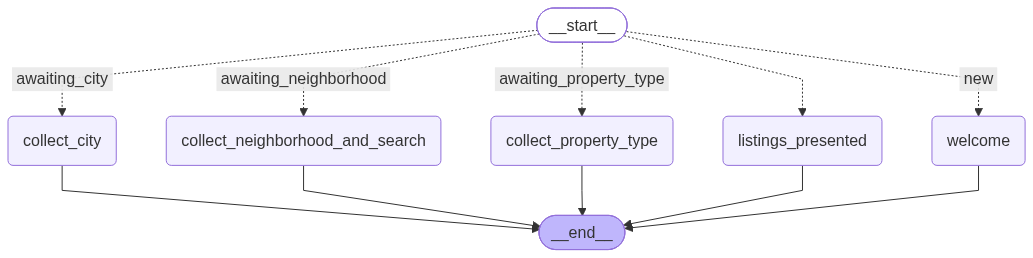

{'phase': 'awaiting_property_type', 'assistant_message': 'Welcome to HomeFinder. What type of property would you like to see: an apartment, house, or workspace?'}
{'phase': 'awaiting_city', 'assistant_message': 'Great. Which city would you like to search in?', 'user_message': 'An apartment, please', 'property_type': 'apartment'}
{'phase': 'awaiting_neighborhood', 'assistant_message': 'Which neighbourhood in that city interests you?', 'user_message': 'Brooklyn', 'property_type': 'apartment', 'city': 'Brooklyn'}
{'phase': 'listings_presented', 'assistant_message': "I found 2 option(s) in Williamsburg:\n1. Sunny one-bedroom near Domino Park — $3,200/month (1 bedrooms, ID APT-101)\n2. Two-bedroom loft with roof access — $4,650/month (2 bedrooms, ID APT-102)\n\nAppointment selection is the next milestone. Type 'restart' to search again.", 'user_message': 'Williamsburg', 'property_type': 'apartment', 'city': 'Brooklyn', 'listings': [{'id': 'APT-101', 'property_type': 'apartment', 'city': 'Br

In [ ]:
from __future__ import annotations

from langgraph.graph import END, START, StateGraph

PROPERTY_TYPES = ("apartment", "house", "workspace")

def _normalized_match(message: str, choices: tuple[str, ...]) -> str | None:
    message = message.casefold()
    return next((choice for choice in choices if choice in message), None)


def welcome(_: RealEstateState) -> dict:
    return {
        "phase": "awaiting_property_type",
        "assistant_message": (
            "Welcome to HomeFinder. What type of property would you like to see: "
            "an apartment, house, or workspace?"
        ),
    }


def listings_presented(_: RealEstateState) -> dict:
    return {
        "assistant_message": (
            "I have already shown the matching listings. Type 'restart' to begin "
            "a new search; appointment selection will be added in the next milestone."
        )
    }


def collect_property_type(state: RealEstateState) -> dict:
    property_type = _normalized_match(state["user_message"], PROPERTY_TYPES)
    if property_type is None:
        return {
            "assistant_message": "Please choose one: apartment, house, or workspace."
        }
    return {
        "property_type": property_type,
        "phase": "awaiting_city",
        "assistant_message": "Great. Which city would you like to search in?",
    }


def collect_city(state: RealEstateState) -> dict:
    city = state["user_message"].strip()
    if not city:
        return {"assistant_message": "Please tell me the city you have in mind."}
    return {
        "city": city.title(),
        "phase": "awaiting_neighborhood",
        "assistant_message": "Which neighbourhood in that city interests you?",
    }


def collect_neighborhood_and_search(state: RealEstateState) -> dict:
    neighborhood = state["user_message"].strip()
    if not neighborhood:
        return {"assistant_message": "Please tell me the neighbourhood you prefer."}

    normalized_neighborhood = neighborhood.title()
    listings = find_listings(
        state["property_type"], state["city"], normalized_neighborhood
    )
    if not listings:
        return {
            "neighborhood": normalized_neighborhood,
            "listings": [],
            "phase": "awaiting_neighborhood",
            "assistant_message": (
                f"I could not find {state['property_type']} listings in "
                f"{normalized_neighborhood}, {state['city']}. "
                "Please try another neighbourhood."
            ),
        }

    formatted_listings = "\n".join(
        f"{index}. {listing['title']} — ${listing['price_per_month']:,}/month "
        f"({listing['bedrooms']} bedrooms, ID {listing['id']})"
        for index, listing in enumerate(listings, start=1)
    )
    return {
        "neighborhood": normalized_neighborhood,
        "listings": listings,
        "phase": "listings_presented",
        "assistant_message": (
            f"I found {len(listings)} option(s) in {normalized_neighborhood}:\n"
            f"{formatted_listings}\n\n"
            "Appointment selection is the next milestone. Type 'restart' to search again."
        ),
    }


def route_turn(state: RealEstateState) -> str:
    return state.get("phase", "awaiting_property_type")

def build_graph():
    """Compile a graph that processes exactly one customer turn at a time."""

    graph = StateGraph(RealEstateState)
    graph.add_node("welcome", welcome)
    graph.add_node("collect_property_type", collect_property_type)
    graph.add_node("collect_city", collect_city)
    graph.add_node("collect_neighborhood_and_search", collect_neighborhood_and_search)
    graph.add_node("listings_presented", listings_presented)

    graph.add_conditional_edges(
        START,
        route_turn,
        {
            "new": "welcome",
            "awaiting_property_type": "collect_property_type",
            "awaiting_city": "collect_city",
            "awaiting_neighborhood": "collect_neighborhood_and_search",
            "listings_presented": "listings_presented",
        },
    )
    graph.add_edge("welcome", END)
    graph.add_edge("collect_property_type", END)
    graph.add_edge("collect_city", END)
    graph.add_edge("collect_neighborhood_and_search", END)
    graph.add_edge("listings_presented", END)

    return graph.compile()

def visualize_graph():
    from IPython.display import Image, display
    app = build_graph()
    display(Image(app.get_graph().draw_mermaid_png()))


def test_graph():
    app = build_graph()
    state = app.invoke({"phase": "new"})
    print(state)
    state.update(app.invoke({**state, "user_message": "An apartment, please"}))
    print(state)
    state.update(app.invoke({**state, "user_message": "Brooklyn"}))
    print(state)
    state.update(app.invoke({**state, "user_message": "Williamsburg"}))
    print(state)



visualize_graph()
test_graph()